# Firechron · Pronóstico de temporada de fuego (equipo BurnInHell)
**NASA Space Apps Challenge 2026 — Sede Mendoza**

Este notebook reúne el código final del pronóstico, de punta a punta:

1. Carga de datos: fuego armonizado (MODIS + VIIRS), clima ERA5-Land e índice ONI.
2. Armado de la tabla celda × mes: variables y objetivo.
3. Separación temporal en entrenamiento, validación y test.
4. Referencias (climatología y persistencia), LightGBM con y sin clima, y red neuronal (MLP).
5. Métricas, importancia de variables y pronóstico del próximo período.

**Qué predice:** con datos hasta el mes M−L, la probabilidad de que el mes M tenga **más focos armonizados que la
mediana histórica** (2003–2019) de ese mismo mes en esa celda de 0,5°. La anticipación principal es **L = 3 meses**.

**Antes:** la limpieza y la armonización de FIRMS están en `scripts/` (ver el README y la guía del equipo). Este
notebook parte de sus resultados.

> Correr desde la carpeta raíz del proyecto (`Hackaton/` o el repo `firecal/`).

## 0. Configuración

In [1]:
import os, warnings, urllib.request, subprocess, sys, json
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=RuntimeWarning)

# --- rutas de entrada (si el notebook está en otra carpeta, ajustar BASE) ---
BASE = "."
FUEGO = f"{BASE}/app/data/app_data.parquet"   # fuego armonizado, celda 0,1° × día
CLIMA = f"{BASE}/data/era5_05.parquet"        # ERA5-Land por celda 0,5° × mes (era5_a_grilla.py)
ONI   = f"{BASE}/data/oni.txt"                # El Niño / La Niña (NOAA CPC)

# --- parámetros del experimento ---
L = 3                          # anticipación en meses (1, 2 o 3)
TRAIN = (2003, 2019)           # años de entrenamiento y de las climatologías
VAL_HASTA, TEST_HASTA = 2022, 2025   # validación 2020–2022 · test 2023–2025 · 2026 = test más reciente
START = (2002, 7)              # desde que vuelan Terra y Aqua juntos
MIN_FOCOS_TRAIN = 50           # celda "activa": al menos 50 focos armonizados en 2003–2019
OUT = f"{BASE}/data/pronostico/notebook_L{L}"
os.makedirs(OUT, exist_ok=True)
CLIMA_VARS = ["t2m_c", "rh", "vpd", "ws", "sm"]
print("Anticipación:", L, "meses · salida en", OUT)

Anticipación: 3 meses · salida en ./data/pronostico/notebook_L3


## 1. Fuego armonizado → grilla de 0,5° por mes
`app_data.parquet` tiene, para cada celda de 0,1° y cada día, los **focos armonizados** (`focos`, en escala VIIRS S-NPP).
Los sumamos a celdas de 0,5° (≈50 km) y meses. También averiguamos cuál es el **último mes completo** con datos.

In [2]:
def month_index(y, m):
    return (np.asarray(y) - START[0]) * 12 + (np.asarray(m) - START[1])

t = pq.read_table(FUEGO, columns=["g_r", "g_c", "date", "focos"])
days = t.column("date").cast(pa.int32()).to_numpy()
d64 = days.astype("datetime64[D]")
m64 = d64.astype("datetime64[M]")
yy = m64.astype("datetime64[Y]").astype(int) + 1970
mm = m64.astype(int) % 12 + 1
fire = pd.DataFrame({"r5": np.floor(t.column("g_r").to_numpy() / 5).astype(int),
                     "c5": np.floor(t.column("g_c").to_numpy() / 5).astype(int),
                     "t": month_index(yy, mm), "focos": t.column("focos").to_numpy()})
fire = fire[fire.t >= 0].groupby(["r5", "c5", "t"], as_index=False).focos.sum()

last = d64.max()
mes_cerrado = (last + np.timedelta64(1, "D")).astype("datetime64[M]") > last.astype("datetime64[M]")
last_full = last.astype("datetime64[M]") - np.timedelta64(0 if mes_cerrado else 1, "M")
T = int(month_index(int(str(last_full)[:4]), int(str(last_full)[5:7]))) + 1   # meses completos: 0..T-1
print(f"Último día con datos: {last} · último mes completo: {last_full} · celdas con fuego: {fire.groupby(['r5','c5']).ngroups:,}")

Último día con datos: 2026-11-14 · último mes completo: 2026-10 · celdas con fuego: 6,363


### Grilla densa tiempo × fila × columna
Pasamos los conteos a un arreglo `F[t, i, j]`, que hace muy simples los rezagos y los vecinos. Agregamos `L` meses
"futuros" vacíos: el último es el mes a pronosticar.

In [3]:
r0, r1 = fire.r5.min() - 1, fire.r5.max() + 1
c0, c1 = fire.c5.min() - 1, fire.c5.max() + 1
NR, NC = r1 - r0 + 1, c1 - c0 + 1
F = np.zeros((T + L, NR, NC), np.float32)
ff = fire[fire.t < T]
F[ff.t.values, ff.r5.values - r0, ff.c5.values - c0] = ff.focos.values

ts = np.arange(T + L)
years = START[0] + (ts + START[1] - 1) // 12
months = (ts + START[1] - 1) % 12 + 1
trn = (years >= TRAIN[0]) & (years <= TRAIN[1])
print("Grilla:", F.shape, "· meses de entrenamiento:", trn.sum())

Grilla: (295, 138, 96) · meses de entrenamiento: 204


## 2. Climatología del fuego y objetivo
Para cada celda y mes del año calculamos, **sólo con 2003–2019**: la mediana (lo normal), el percentil 75 y la
fracción de años con fuego. Así ni el test ni la validación se filtran en la definición de "normal".

**Objetivo:** `y = 1` si los focos del mes superan la mediana de ese mes en esa celda; si no, `y = 0`.

In [4]:
med = np.zeros((13, NR, NC), np.float32); p75 = med.copy(); frac = med.copy()
for m in range(1, 13):
    sel = trn & (months == m)
    med[m] = np.median(F[sel], axis=0)
    p75[m] = np.percentile(F[sel], 75, axis=0)
    frac[m] = (F[sel] > 0).mean(axis=0)

activa = F[trn].sum(axis=0) >= MIN_FOCOS_TRAIN
ii, jj = np.nonzero(activa)
print(f"Celdas activas: {len(ii):,}")

LF = np.log1p(F)                       # focos en escala log
Lmed = np.log1p(med)
ANOM = LF - Lmed[months]               # anomalía log respecto de lo normal de ese mes
P = np.pad(F, ((0, 0), (1, 1), (1, 1)))
VEC = sum(P[:, 1 + di:1 + di + NR, 1 + dj:1 + dj + NC]   # suma de los 8 vecinos
          for di in (-1, 0, 1) for dj in (-1, 0, 1) if (di, dj) != (0, 0))

Celdas activas: 5,245


## 3. Clima (ERA5-Land) y El Niño
Pasamos cada variable a la misma grilla y calculamos **anomalías** contra su climatología 2003–2019.
Para la lluvia usamos acumulados de 1, 3 y 6 meses como cociente logarítmico contra lo normal.

In [5]:
cl = pd.read_parquet(CLIMA)
cl["t"] = month_index(cl.year, cl.month)
cl = cl[(cl.t >= 0) & (cl.t < T + L) & cl.r5.between(r0, r1) & cl.c5.between(c0, c1)]
W = {}
for v in CLIMA_VARS + ["pr_mm"]:
    arr = np.full((T + L, NR, NC), np.nan, np.float32)
    arr[cl.t.values, cl.r5.values - r0, cl.c5.values - c0] = cl[v].values
    W[v] = arr
pr = W.pop("pr_mm")
for k in (1, 3, 6):
    acc = np.full_like(pr, np.nan)
    for t_ in range(k - 1, T + L):
        acc[t_] = pr[t_ - k + 1:t_ + 1].sum(axis=0)
    W[f"pr{k}"] = acc

WA = {}
for v, arr in W.items():
    clim = np.full((13, NR, NC), np.nan, np.float32)
    for m in range(1, 13):
        clim[m] = np.nanmean(arr[trn & (months == m)], axis=0)
    WA[v] = np.log((arr + 1) / (clim[months] + 1)) if v.startswith("pr") else arr - clim[months]
print("Variables de clima:", list(WA))

# ONI: anomalía de la estación de 3 meses, indexada por (año, mes central)
if not os.path.exists(ONI):
    urllib.request.urlretrieve("https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt", ONI)
seas = {s: i + 1 for i, s in enumerate(["DJF","JFM","FMA","MAM","AMJ","MJJ","JJA","JAS","ASO","SON","OND","NDJ"])}
oni = {}
for line in open(ONI):
    p_ = line.split()
    if len(p_) >= 4 and p_[0] in seas:
        oni[(int(p_[1]), seas[p_[0]])] = float(p_[3])
print("ONI: valores hasta", max(oni))

Variables de clima: ['t2m_c', 'rh', 'vpd', 'ws', 'sm', 'pr1', 'pr3', 'pr6']
ONI: valores hasta (2026, 9)


## 4. Tabla de entrenamiento
Una fila por **celda activa × mes objetivo M**. Todas las variables usan información **hasta M−L** (lo que se sabe al
emitir el pronóstico):

| Grupo | Variables |
|---|---|
| Posición y época | `lat`, `lon`, `mes_sin`, `mes_cos` |
| Lo normal para M | `clim_med`, `clim_p75`, `clim_frac` |
| Fuego reciente | `lag1..3` y `anom1..3` (los 3 meses más recientes: M−L, M−L−1, M−L−2), `anom_1a3`, `vecinos1` |
| Mismo mes del año anterior | `lag12`, `anom12` |
| Clima (mes M−L) | `c_t2m_c`, `c_rh`, `c_vpd`, `c_ws`, `c_sm`, `c_pr1`, `c_pr3`, `c_pr6` |
| El Niño | `oni` (estación centrada en M−L−1, ya publicada) |

In [6]:
filas = []
for t_ in range(max(12, L + 2), T + L):
    if T <= t_ < T + L - 1:
        continue                        # meses intermedios sin datos suficientes para esta anticipación
    y_, m_ = int(years[t_]), int(months[t_])
    n = len(ii)
    d = {"r5": ii + r0, "c5": jj + c0, "year": np.full(n, y_), "month": np.full(n, m_),
         "lat": (ii + r0 + 0.5) * 0.5, "lon": (jj + c0 + 0.5) * 0.5,
         "mes_sin": np.full(n, np.sin(2 * np.pi * m_ / 12)), "mes_cos": np.full(n, np.cos(2 * np.pi * m_ / 12)),
         "clim_med": Lmed[m_][ii, jj], "clim_p75": np.log1p(p75[m_][ii, jj]), "clim_frac": frac[m_][ii, jj],
         "lag1": LF[t_ - L][ii, jj], "lag2": LF[t_ - L - 1][ii, jj], "lag3": LF[t_ - L - 2][ii, jj],
         "lag12": LF[t_ - 12][ii, jj],
         "anom1": ANOM[t_ - L][ii, jj], "anom2": ANOM[t_ - L - 1][ii, jj], "anom3": ANOM[t_ - L - 2][ii, jj],
         "anom12": ANOM[t_ - 12][ii, jj], "vecinos1": np.log1p(VEC[t_ - L][ii, jj])}
    d["anom_1a3"] = (d["anom1"] + d["anom2"] + d["anom3"]) / 3
    for v, arr in WA.items():
        d[f"c_{v}"] = arr[t_ - L][ii, jj]
    tt = t_ - L - 1
    d["oni"] = np.full(n, oni.get((int(years[tt]), int(months[tt])), np.nan))
    if t_ < T:
        d["focos"] = F[t_][ii, jj]
        d["y"] = (F[t_][ii, jj] > med[m_][ii, jj]).astype(np.int8)
    else:
        d["focos"] = np.full(n, np.nan); d["y"] = np.full(n, -1, np.int8)   # mes a pronosticar
    filas.append(pd.DataFrame(d))
df = pd.concat(filas, ignore_index=True)
print(f"Tabla: {len(df):,} filas × {df.shape[1]} columnas")
fy, fm = int(years[T + L - 1]), int(months[T + L - 1])
print(f"Con datos hasta {years[T-1]}-{months[T-1]:02d} se pronostica {fy}-{fm:02d}")

Tabla: 1,473,845 filas × 32 columnas
Con datos hasta 2026-10 se pronostica 2027-01


## 5. Separación temporal (train / validación / test)
Separamos **por años, nunca al azar**: si no, el modelo vería información del futuro y las métricas saldrían infladas.

- **train** 2003–2019: para aprender (y para calcular "lo normal").
- **val** 2020–2022: para decidir cuándo frenar el entrenamiento.
- **test** 2023–2025: evaluación principal; el modelo nunca lo vio.
- **extra** 2026: la prueba más reciente.
- **pronostico**: el mes futuro, sin respuesta conocida.

In [7]:
df["split"] = np.select([df.y < 0, df.year <= TRAIN[1], df.year <= VAL_HASTA, df.year <= TEST_HASTA],
                        ["pronostico", "train", "val", "test"], "extra")
df.to_parquet(f"{OUT}/tabla.parquet", index=False)
print(df.groupby("split").agg(filas=("y", "size"), prop_por_encima=("y", lambda s: (s == 1).mean())).round(3))

NO_FEAT = {"r5", "c5", "year", "month", "focos", "y", "split"}
feats_all = [c for c in df.columns if c not in NO_FEAT]
feats_fuego = [c for c in feats_all if not c.startswith("c_") and c != "oni"]
ccols = [c for c in feats_all if c.startswith("c_")]
tr, va = df[df.split == "train"], df[df.split == "val"]
print(len(feats_fuego), "variables de fuego ·", len(feats_all) - len(feats_fuego), "de clima/ENSO")

              filas  prop_por_encima
split                               
extra         52450            0.329
pronostico     5245            0.000
test         188820            0.403
train       1038510            0.350
val          188820            0.439
17 variables de fuego · 9 de clima/ENSO


## 6. Red neuronal (MLP) — en un proceso aparte
En Mac, PyTorch y LightGBM traen cada uno su propia librería OpenMP y **juntos en el mismo proceso se cuelgan o dan
*segmentation fault***. Por eso la red se escribe a un archivo y se ejecuta con su propio Python. Se corre **antes**
de importar LightGBM.

Arquitectura: entradas estandarizadas (+1 indicador de clima faltante) → 128 ReLU → Dropout 0,2 → 64 ReLU →
Dropout 0,2 → 1 (sigmoide). Pérdida BCE, AdamW (lr 1e-3), lotes de 4.096, parada temprana por AUC de validación
(paciencia 5).

In [8]:
%%writefile mlp_notebook.py
import sys, os
import numpy as np, pandas as pd, torch
from torch import nn

tabla, out = sys.argv[1], sys.argv[2]
df = pd.read_parquet(tabla)
NO_FEAT = {"r5", "c5", "year", "month", "focos", "y", "split"}
feats = [c for c in df.columns if c not in NO_FEAT]
ccols = [c for c in feats if c.startswith("c_")]
tr = df[(df.split == "train") & df[ccols].notna().all(axis=1)]
va = df[df.split == "val"]
mu, sd = tr[feats].mean(), tr[feats].std().replace(0, 1)

def prep(d):
    x = ((d[feats] - mu) / sd).astype("float32")
    falta = x.isna().any(axis=1).astype("float32").to_numpy()[:, None]
    return np.hstack([x.fillna(0).to_numpy(), falta]).astype("float32")

def auc(y, p):                       # AUC por rangos (sin scikit-learn)
    r = pd.Series(p).rank().to_numpy(); y = np.asarray(y)
    n1 = (y == 1).sum(); n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

Xtr, ytr = torch.tensor(prep(tr)), torch.tensor(tr.y.to_numpy().astype("float32"))
Xva = torch.tensor(prep(va))
torch.manual_seed(42)
net = nn.Sequential(nn.Linear(Xtr.shape[1], 128), nn.ReLU(), nn.Dropout(0.2),
                    nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.2), nn.Linear(64, 1))
opt = torch.optim.AdamW(net.parameters(), lr=1e-3, weight_decay=1e-4)
lossf = nn.BCEWithLogitsLoss()
best, best_state, pac = -1, None, 0
for ep in range(40):
    net.train()
    perm = torch.randperm(len(Xtr))
    for k in range(0, len(perm), 4096):
        idx = perm[k:k + 4096]
        opt.zero_grad(); lossf(net(Xtr[idx]).squeeze(1), ytr[idx]).backward(); opt.step()
    net.eval()
    with torch.no_grad():
        s = auc(va.y.to_numpy(), torch.sigmoid(net(Xva).squeeze(1)).numpy())
    print(f"época {ep + 1:2d}  AUC val {s:.4f}", flush=True)
    if s > best + 1e-4:
        best, pac, best_state = s, 0, {k: v.clone() for k, v in net.state_dict().items()}
    else:
        pac += 1
        if pac >= 5: break
net.load_state_dict(best_state); net.eval()
with torch.no_grad():
    p = torch.sigmoid(net(torch.tensor(prep(df))).squeeze(1)).numpy()
df[["r5", "c5", "year", "month"]].assign(p_mlp=p).to_parquet(os.path.join(out, "pred_mlp.parquet"), index=False)
torch.save(best_state, os.path.join(out, "mlp.pt"))
print(f"Listo. Mejor AUC val: {best:.4f}")

Writing mlp_notebook.py


In [9]:
r = subprocess.run([sys.executable, "mlp_notebook.py", f"{OUT}/tabla.parquet", OUT], capture_output=True, text=True)
print(r.stdout[-1500:], r.stderr[-1500:])

época  1  AUC val 0.6691
época  2  AUC val 0.6661
época  3  AUC val 0.6655
época  4  AUC val 0.6609
época  5  AUC val 0.6655
época  6  AUC val 0.6625
Listo. Mejor AUC val: 0.6691
 


## 7. Referencias y LightGBM
Todos los modelos responden **la misma pregunta** (probabilidad de "por encima de lo normal"); cambia la información
que usan:
- **Climatología:** frecuencia histórica de "por encima" en esa celda y ese mes del año.
- **Persistencia:** probabilidad histórica de "por encima" según si el último mes conocido vino por encima o no.
- **LightGBM sólo fuego** y **LightGBM con clima + ONI**: parada temprana por AUC de validación.

In [10]:
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, brier_score_loss

clim = tr.groupby(["r5", "c5", "month"]).y.mean().rename("p_clim")
pers = tr.assign(arriba=tr.anom1 > 0).groupby(["month", "arriba"]).y.mean().rename("p_pers")
df = df.join(clim, on=["r5", "c5", "month"])
df["p_clim"] = df.p_clim.fillna(tr.y.mean())
df = df.assign(arriba=df.anom1 > 0).join(pers, on=["month", "arriba"]).drop(columns="arriba")

PARAMS = dict(objective="binary", metric=["auc", "binary_logloss"], learning_rate=0.05, num_leaves=63,
              min_data_in_leaf=200, feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1,
              lambda_l2=1.0, verbose=-1, seed=42)

def entrenar_lgb(trd, feats, nombre):
    m = lgb.train(PARAMS, lgb.Dataset(trd[feats], trd.y), 3000,
                  valid_sets=[lgb.Dataset(va[feats], va.y)],
                  callbacks=[lgb.early_stopping(100, first_metric_only=True, verbose=False)])
    m.save_model(f"{OUT}/{nombre}.txt")
    print(f"{nombre}: {m.best_iteration} árboles")
    return m

m_f = entrenar_lgb(tr, feats_fuego, "lgb_fuego")
df["p_lgb_fuego"] = m_f.predict(df[feats_fuego], num_iteration=m_f.best_iteration)
m_c = entrenar_lgb(tr[tr[ccols].notna().all(axis=1)], feats_all, "lgb_clima")
df["p_lgb_clima"] = m_c.predict(df[feats_all], num_iteration=m_c.best_iteration)

pm = f"{OUT}/pred_mlp.parquet"
modelos = ["p_clim", "p_pers", "p_lgb_fuego", "p_lgb_clima"]
if os.path.exists(pm):
    df = df.merge(pd.read_parquet(pm), on=["r5", "c5", "year", "month"], how="left")
    modelos.append("p_mlp")

lgb_fuego: 736 árboles


lgb_clima: 85 árboles


## 8. Evaluación
- **AUC:** ¿pone más probabilidad en los meses que efectivamente vinieron por encima? (0,5 = azar, 1 = perfecto).
- **Brier:** error cuadrático de las probabilidades. **BSS** = 1 − Brier(modelo) / Brier(climatología): cuánto
  menos error que la referencia.
- **Acierto:** ≥ 50 % se toma como "por encima". Ojo: decir siempre "no" ya acierta el ~60 %.

In [11]:
def metricas(d, col):
    b = brier_score_loss(d.y, d[col])
    return {"AUC": roc_auc_score(d.y, d[col]), "Brier": b,
            "BSS": 1 - b / brier_score_loss(d.y, d.p_clim), "Acierto": ((d[col] >= 0.5) == d.y).mean()}

res = []
for sp in ["val", "test", "extra"]:
    d = df[df.split == sp]
    dc = d[d[ccols].notna().all(axis=1)]
    for mo in modelos:
        dd = dc if mo in ("p_lgb_clima", "p_mlp") else d
        if len(dd) < 0.9 * len(d):
            continue
        res.append({"split": sp, "modelo": mo[2:], **metricas(dd, mo)})
met = pd.DataFrame(res)
met.to_csv(f"{OUT}/metricas.csv", index=False)
met.round(3)

,split,modelo,AUC,Brier,BSS,Acierto
0,val,clim,0.629,0.236,0.000,0.581
1,val,pers,0.570,0.250,-0.055,0.562
2,val,lgb_fuego,0.685,0.223,0.057,0.621
3,val,lgb_clima,0.669,0.231,0.025,0.600
4,val,mlp,0.669,0.233,0.017,0.596
5,test,clim,0.612,0.231,0.000,0.607
6,test,pers,0.577,0.239,-0.036,0.592
7,test,lgb_fuego,0.705,0.213,0.077,0.655
8,test,lgb_clima,0.688,0.218,0.058,0.643
9,test,mlp,0.674,0.223,0.034,0.629


### Qué cuenta como acierto (test, mejor LightGBM)

In [12]:
t_ = df[df.split == "test"]
p_ = t_.p_lgb_fuego >= 0.5; y_ = t_.y == 1
print(f"Casos 'por encima de lo normal': {y_.mean():.0%}")
print(f"De ellos, anticipados por el modelo: {(p_ & y_).sum() / y_.sum():.0%}  (climatología: {((t_.p_clim >= .5) & y_).sum() / y_.sum():.0%})")
print(f"Cuando dijo 'por encima', acertó: {(p_ & y_).sum() / p_.sum():.0%}")
cal = pd.cut(t_.p_lgb_fuego, [0, .2, .4, .6, .8, 1.0001], right=False)
print("\nCalibración (probabilidad dicha → frecuencia real):")
print(t_.groupby(cal, observed=True).y.agg(casos="size", paso_de_verdad="mean").round(2))

Casos 'por encima de lo normal': 40%
De ellos, anticipados por el modelo: 38%  (climatología: 11%)
Cuando dijo 'por encima', acertó: 62%

Calibración (probabilidad dicha → frecuencia real):
             casos  paso_de_verdad
p_lgb_fuego                       
[0.0, 0.2)   36214            0.15
[0.2, 0.4)   56506            0.32
[0.4, 0.6)   80113            0.52
[0.6, 0.8)   15356            0.67
[0.8, 1.0)     631            0.75


## 9. Figuras: métricas e importancia de variables

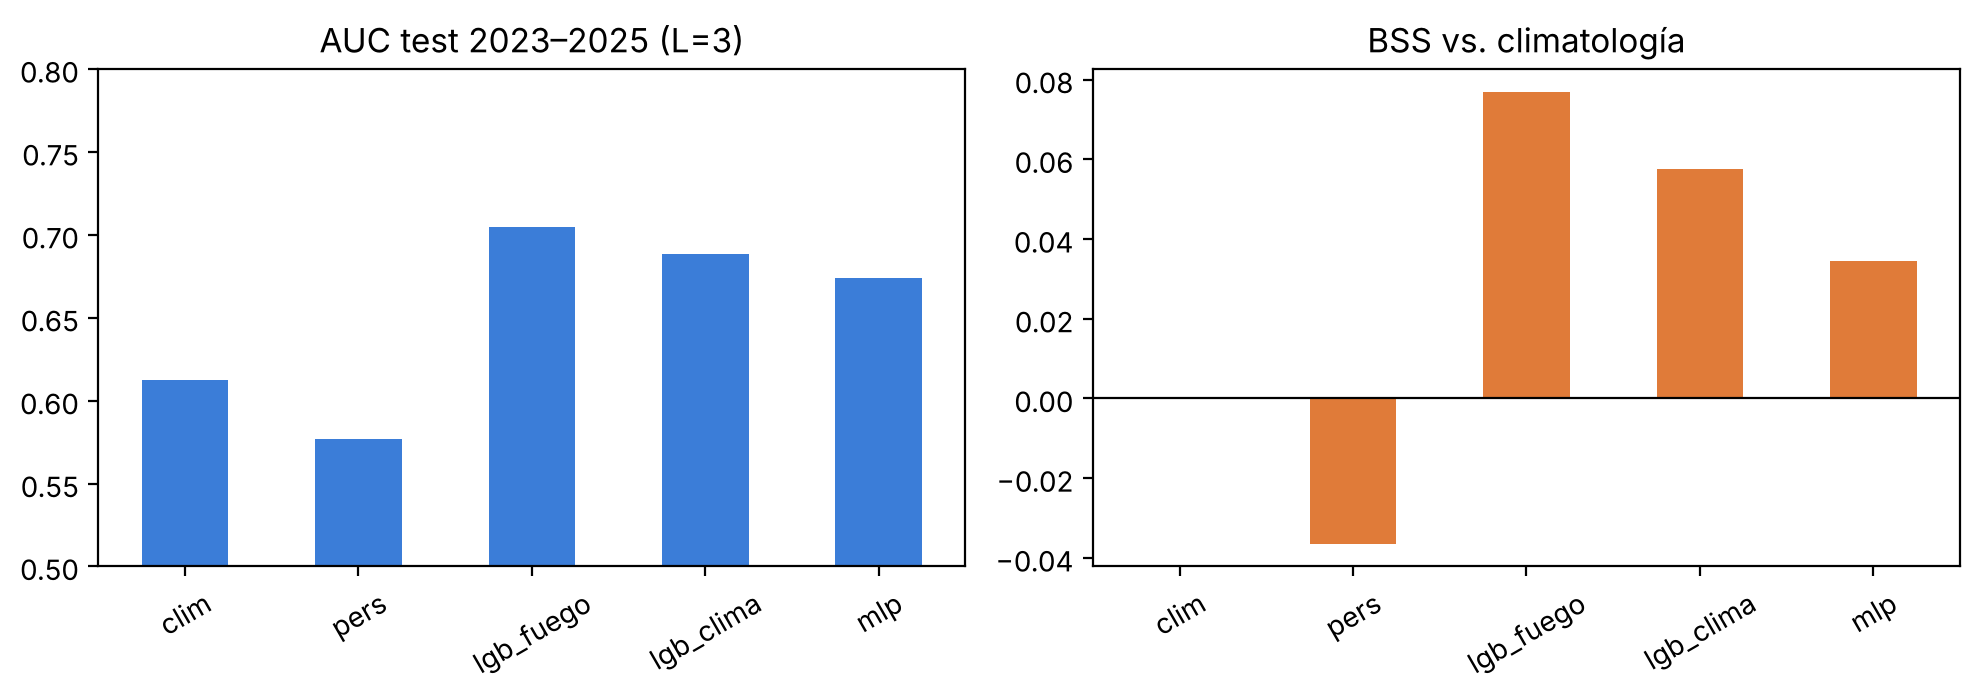

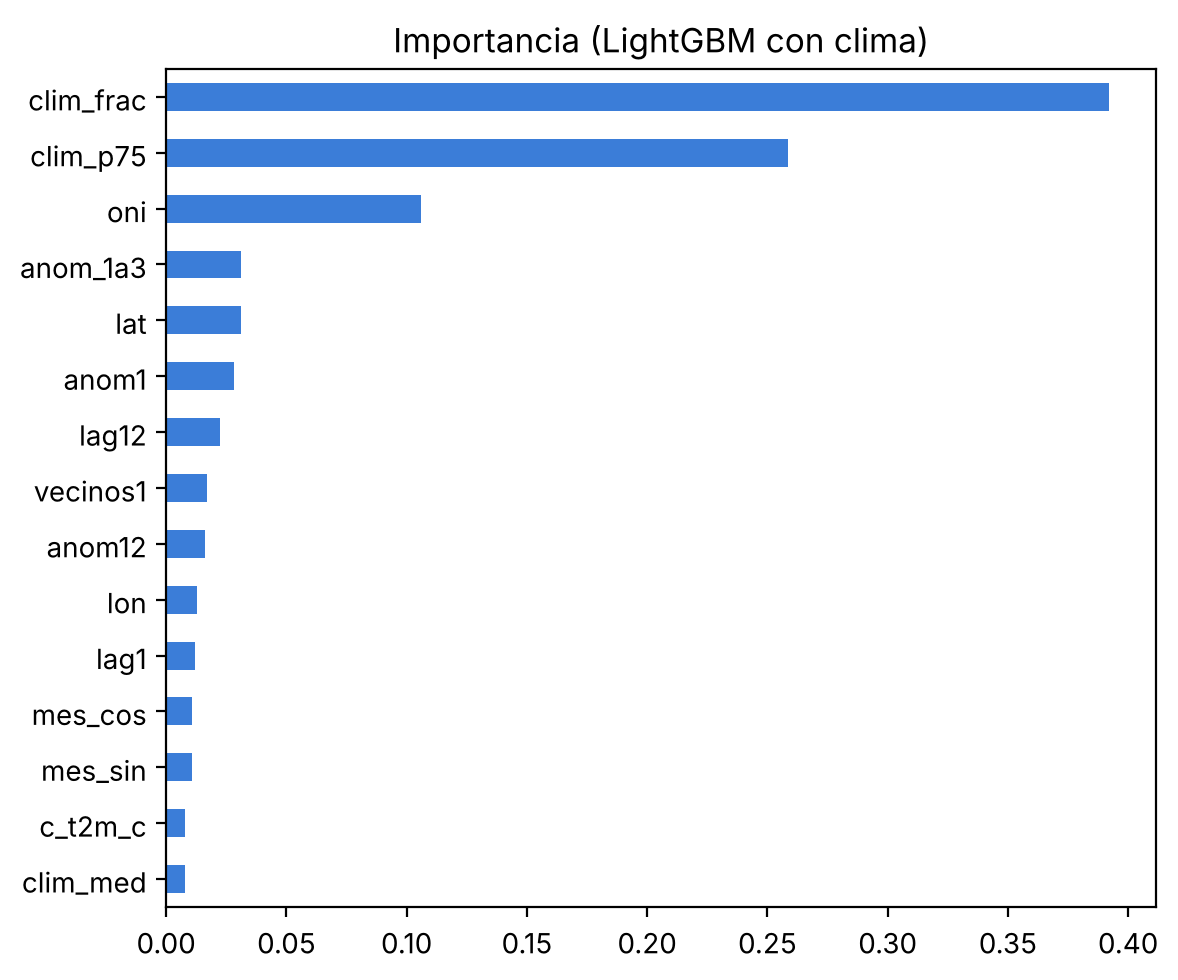

In [13]:
tt_ = met[met.split == "test"].set_index("modelo")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
tt_.AUC.plot.bar(ax=ax[0], color="#3B7DD8"); ax[0].set_ylim(0.5, 0.8); ax[0].set_title(f"AUC test 2023–2025 (L={L})")
tt_.BSS.plot.bar(ax=ax[1], color="#E07B39"); ax[1].axhline(0, color="k", lw=.8); ax[1].set_title("BSS vs. climatología")
for a_ in ax: a_.tick_params(axis="x", rotation=30); a_.set_xlabel("")
plt.tight_layout(); plt.savefig(f"{OUT}/metricas.png", dpi=150); plt.show()

imp = pd.Series(m_c.feature_importance("gain"), index=feats_all).sort_values(ascending=False)
(imp / imp.sum()).head(15)[::-1].plot.barh(figsize=(6, 5), color="#3B7DD8", title="Importancia (LightGBM con clima)")
plt.tight_layout(); plt.savefig(f"{OUT}/importancias.png", dpi=150); plt.show()

## 10. Pronóstico del próximo período
Se usa el LightGBM con mejor AUC de validación (con clima si hay datos del mes de emisión).

Pronóstico 2027-01 (lgb_fuego): 19% de las celdas con prob ≥ 50 %


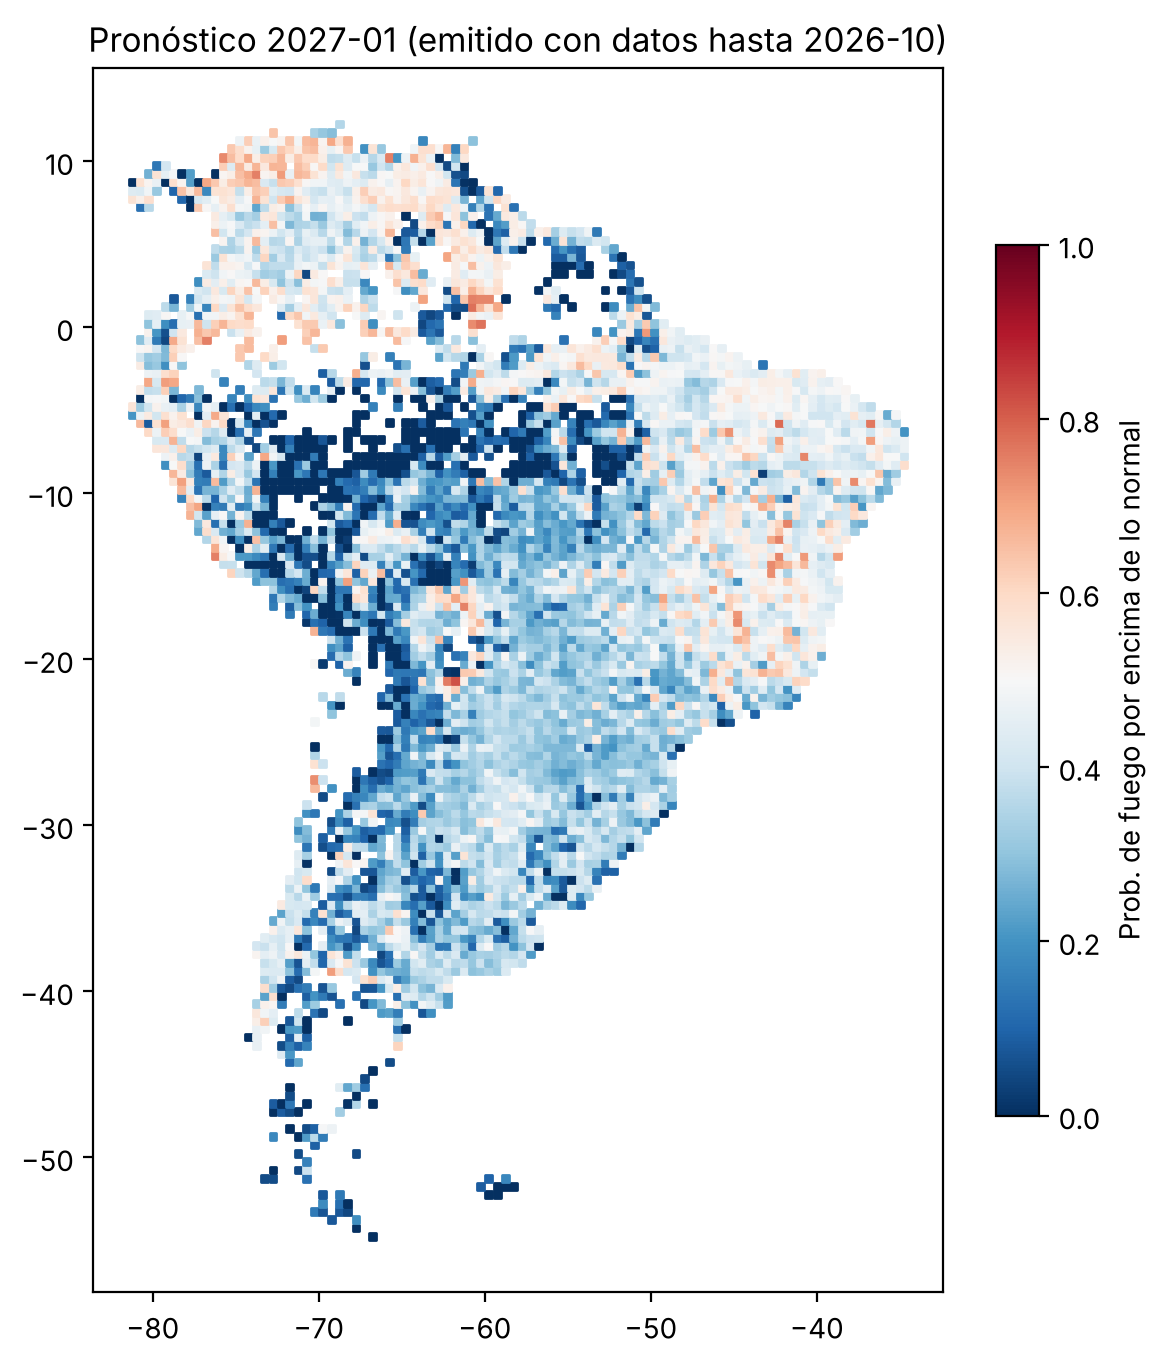

In [14]:
fc = df[df.split == "pronostico"].copy()
mv = met[met.split == "val"].set_index("modelo").AUC
usa_clima = fc[ccols].notna().all(axis=1).mean() > 0.9 and mv["lgb_clima"] > mv["lgb_fuego"]
fc["prob"] = fc.p_lgb_clima if usa_clima else fc.p_lgb_fuego
modelo_fc = "lgb_clima" if usa_clima else "lgb_fuego"
fc[["r5", "c5", "year", "month", "lat", "lon", "prob", "p_clim"]].to_parquet(f"{OUT}/pronostico.parquet", index=False)
print(f"Pronóstico {fy}-{fm:02d} ({modelo_fc}): {(fc.prob >= .5).mean():.0%} de las celdas con prob ≥ 50 %")

fig, ax = plt.subplots(figsize=(6, 7))
sc = ax.scatter(fc.lon, fc.lat, c=fc.prob, s=6, cmap="RdBu_r", vmin=0, vmax=1, marker="s")
fig.colorbar(sc, ax=ax, shrink=.7, label="Prob. de fuego por encima de lo normal")
ax.set_aspect("equal"); ax.set_title(f"Pronóstico {fy}-{fm:02d} (emitido con datos hasta {years[T-1]}-{months[T-1]:02d})")
plt.tight_layout(); plt.savefig(f"{OUT}/pronostico.png", dpi=150); plt.show()

---
**Fuentes:** NASA FIRMS (MODIS C6.1, VIIRS 375 m S-NPP/NOAA-20) · Copernicus C3S ERA5-Land monthly · NOAA CPC ONI.
Código: github.com/lautarodiazopazo/firecal (MIT). Asistencia de IA: Claude (Anthropic).